In [1]:
from modules.dataset.make_dataset import make_dataset, dataset_split, NpzDataPipeline
from modules.nn import BranchedCoughCNN, DefaultCNN, FocalLoss
import polars as pl
import numpy as np
import torch
from torchinfo import summary
from torch.utils.data import Subset
import torch.nn as nn
from torch.utils.data import WeightedRandomSampler
import torch.optim as optim
from modules.preprocessing.dataframe_process import filter_coughvid_df

In [2]:
def compute_imbalance_weights(class_counts: torch.Tensor | list, device: str="cpu") -> torch.Tensor:
    if not isinstance(class_counts, torch.Tensor):
        counts = torch.tensor(class_counts, dtype=torch.float32)
    else:
        counts = class_counts.float()
        
    sampler_weights = 1.0 / counts
    loss_weights = counts.max() / counts
    
    return sampler_weights.to(device), loss_weights.to(device)

In [3]:
dataset: NpzDataPipeline = NpzDataPipeline("data\\final_processed_dataset.npz")
device: torch.types.Device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [4]:

BETAS: list[float] = [0.999, 0.995, 0.99] 
def make_beta_weights(class_counts: list[int], betas: list[float]) -> list[list[float]]:
    beta_weights: list[list[float]] = []
    for b in betas:
        effective_num = 1.0 - np.power(b, class_counts)
        weights = (1.0 - b) / effective_num
        beta_weights.append(
            weights / np.sum(weights) * len(class_counts)
        )
    return beta_weights

In [5]:
# ---- Experiment setup (shared) ----
from modules.dataset.make_dataset import AugmentedSubset
from modules.preprocessing.audio_process import WaveformAugmentor, SpecAugmentations, MelSpectrogramPipeline, SpectMFCCPipeline
from tqdm.auto import tqdm

num_epochs: int = 60
SEED: int = 42  # identical split across all 3 experiments
BATCH_SIZE: int = 128

# ponytail: fill these manually (healthy, COVID-19, symptomatic)
CLASS_COUNTS: list[int] = [35674, 2398, 9775]
CLASS_WEIGHTS: torch.Tensor = torch.tensor([0.447, 6.649, 1.631], device=device)
# compute_imbalance_weights returns (sampler_weights, loss_weights) — only loss_weights goes to FocalLoss
sampler_weights, loss_weights = compute_imbalance_weights(CLASS_COUNTS, device)

mel_train_plain: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)  # no spec aug
mel_train_spec: SpectMFCCPipeline = SpectMFCCPipeline(transforms=SpecAugmentations(), combind=True).to(device)
mel_eval: SpectMFCCPipeline = SpectMFCCPipeline(combind=True).to(device)         # plain for validation

# speed: compile only the eval mel path; train paths stay eager (spec-aug masks/augmentor randomize per step)
mel_eval = torch.compile(mel_eval) if device.type == "cuda" else mel_eval  # CPU inductor needs MSVC cl.exe; skip

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

c:\Users\drewq\Documents\code\GitHub\senior_design\Senior_Design\project_notebooks\.venv\Lib\site-packages\torchaudio\functional\functional.py:581: UserWarning: At least one mel filterbank has all zero values. The value for `n_mels` (256) may be set too high. Or, the value for `n_freqs` (513) may be set too low.
  warnings.warn(


In [6]:
# ---- Seeded split (shared across experiments) ----
dataset.load_data()

train_subset, val_subset, _ = dataset_split(dataset, seed=SEED)

In [7]:
class_counts = torch.tensor(CLASS_COUNTS)
class_weights = 1.0 / class_counts

# 2. Extract labels ONLY for the samples present in this specific Subset
# (Assumes your original underlying dataset stores labels in '.targets' or '.labels')
original_dataset = train_subset.dataset
subset_indices = train_subset.indices

# Map the subset indices back to their true labels
subset_labels = [original_dataset.labels[idx] for idx in subset_indices]

# 3. Assign the correct weight to every sample in the subset
sample_weights = [class_weights[label] for label in subset_labels]

# 4. Create the sampler using the subset's total length
train_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

In [8]:
_model = DefaultCNN(num_classes=3)
summary(_model, input_size=(64, 3, 296 ,32))

Layer (type:depth-idx)                   Output Shape              Param #
DefaultCNN                               [64, 3]                   --
├─Sequential: 1-1                        [64, 128, 37, 4]          --
│    └─DepthwiseSeparableBlock: 2-1      [64, 32, 148, 16]         --
│    │    └─Sequential: 3-1              [64, 32, 148, 16]         193
│    └─DepthwiseSeparableBlock: 2-2      [64, 64, 74, 8]           --
│    │    └─Sequential: 3-2              [64, 64, 74, 8]           2,528
│    └─DepthwiseSeparableBlock: 2-3      [64, 128, 37, 4]          --
│    │    └─Sequential: 3-3              [64, 128, 37, 4]          9,152
├─Sequential: 1-2                        [64, 3]                   --
│    └─Flatten: 2-4                      [64, 18944]               --
│    └─Linear: 2-5                       [64, 256]                 4,849,920
│    └─LeakyReLU: 2-6                    [64, 256]                 --
│    └─Dropout: 2-7                      [64, 256]                 --
│

In [15]:
# ---- Experiment runner (based on the base training loop) ----
from sklearn.metrics import f1_score

def run_experiment(name: str, use_wave: bool, use_spec: bool) -> dict[str, list[float]]:
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": [], "val_F1":[]}

    # Fresh model/optimizer per experiment so runs are independent
    criterion: nn.Module = nn.CrossEntropyLoss(label_smoothing=0.1)
    
    if device.type == "cuda":
        model: nn.Module  = torch.compile(DefaultCNN(num_classes=3)).to(device)  
    else:
        model = DefaultCNN(num_classes=3).to(device)  # speed: compile only on CUDA
        
    optimizer: optim.AdamW = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    scaler: torch.amp.GradScaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
    scheduler: optim.lr_scheduler.CosineAnnealingLR = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-6
    )

    mel_train: SpectMFCCPipeline = mel_train_spec if use_spec else mel_train_plain

    # Train loader: AugmentedSubset (WaveformAugmentor) when use_wave, else plain Subset
    train_ds: AugmentedSubset | Subset = AugmentedSubset(
        dataset, train_subset.indices, 
        WaveformAugmentor(16_000)
    ) if use_wave else Subset(dataset, train_subset.indices)
    
    train_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        train_ds, BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4, sampler=train_sampler  # speed: no worker respawn / keep queues full
    )
    
    val_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(dataset, val_subset.indices), BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,
    )

    for epoch in range(num_epochs):
        # Training Phase
        model.train()
        running_loss = 0.0
  
        for waveforms, labels in tqdm(train_loader, desc=f"[{name}] train {epoch+1}/{num_epochs}", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            labels = labels.long().to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Features must run in fp32 OUTSIDE autocast: TimeStretch/complex spectrogram
            # ops produce NaN under fp16 autocast
            images = mel_train(waveforms, labels)  # (B, 3, F, T) — pipeline already returns 3 channels
            if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                images = images.unsqueeze(0)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

        scheduler.step()

        # Validation Phase
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        
        all_preds = []
        all_targets = []

        with torch.inference_mode():
            for waveforms, labels in tqdm(val_loader, desc=f"[{name}] val {epoch+1}/{num_epochs}", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                labels = labels.long().to(device, non_blocking=True)

                images = mel_eval(waveforms)  # no labels -> no spec aug; fp32 outside autocast
                if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                    images = images.unsqueeze(0)

                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    
                all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                all_targets.extend(labels.cpu().numpy())

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_macro_f1 = f1_score(all_targets, all_preds, average='macro')
        train_epoch_loss = running_loss / len(train_loader)
        val_epoch_loss = val_loss / len(val_loader)
        val_accuracy = 100.0 * correct / total

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_F1"].append(val_macro_f1)
        history["val_acc"].append(val_accuracy)

        print(f"[{name}] Epoch [{epoch+1}/{num_epochs}] -> "
              f"Train Loss: {train_epoch_loss:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} | "
              f"Val F1: {val_macro_f1:.4f} | "
              f"Val Acc: {val_accuracy:.2f}%")

    return history


In [16]:
results: dict[str, dict[str, list[float]]] = {}

In [17]:
import sys, atexit
LOG_PATH = r"logs/augmentation_experiment_2026-10-22.txt"
_logf = open(LOG_PATH, "w", encoding="utf-8")  # "a" to append across reruns
sys.stdout = _logf
sys.stderr = _logf
atexit.register(_logf.close)

<function TextIOWrapper.close()>

In [ ]:


# Then the wave/spec experiments
print("STARTING AUGMENTATION EXPERIMENT")
print("wave + spec EXPERIMENT")
results["both"] = run_experiment("both (wave + spec)", use_wave=True, use_spec=True)
print("\nwave only EXPERIMENT")
results["wave_only"] = run_experiment("wave only", use_wave=True, use_spec=False)
print("\nspec only EXPERIMENT")
results["spec_only"] = run_experiment("spec only", use_wave=False, use_spec=True)



# Comparison table
print("\n=== Experiment Comparison ===")
print(f"{'Experiment':<20} {'Final Val Acc':>12} {'Final Val Loss':>13} {'Final Val F1':>13}")
for name, hist in results.items():
    best_acc: float = hist["val_acc"][-1]
    min_loss: float = hist["val_loss"][-1]
    max_f1: float = hist["val_F1"][-1]
    df = pl.DataFrame(hist)
    df.write_csv(f'{name}_experiment_stats.csv')
    print(f"{name:<20} {best_acc:>11.2f}% {min_loss:>13.4f} {max_f1:>13.4f}")

[both (wave + spec)] train 1/60:   0%|          | 0/300 [00:28<?, ?it/s]

[both (wave + spec)] val 1/60:   0%|          | 0/38 [00:00<?, ?it/s]

[both (wave + spec)] train 2/60:   0%|          | 0/300 [00:00<?, ?it/s]

[both (wave + spec)] val 2/60:   0%|          | 0/38 [00:00<?, ?it/s]

[both (wave + spec)] train 3/60:   0%|          | 0/300 [00:00<?, ?it/s]

...

[both (wave + spec)] train 49/60:   0%|          | 0/300 [00:00<?, ?it/s]

[both (wave + spec)] val 49/60:   0%|          | 0/38 [00:00<?, ?it/s]

[both (wave + spec)] train 50/60:   0%|          | 0/300 [00:00<?, ?it/s]

[both (wave + spec)] val 50/60:   0%|          | 0/38 [00:00<?, ?it/s]

[both (wave + spec)] train 51/60:   0%|          | 0/300 [00:00<?, ?it/s]

In [ ]:
from plotting.experiment_plots import plot_history, plot_comparison

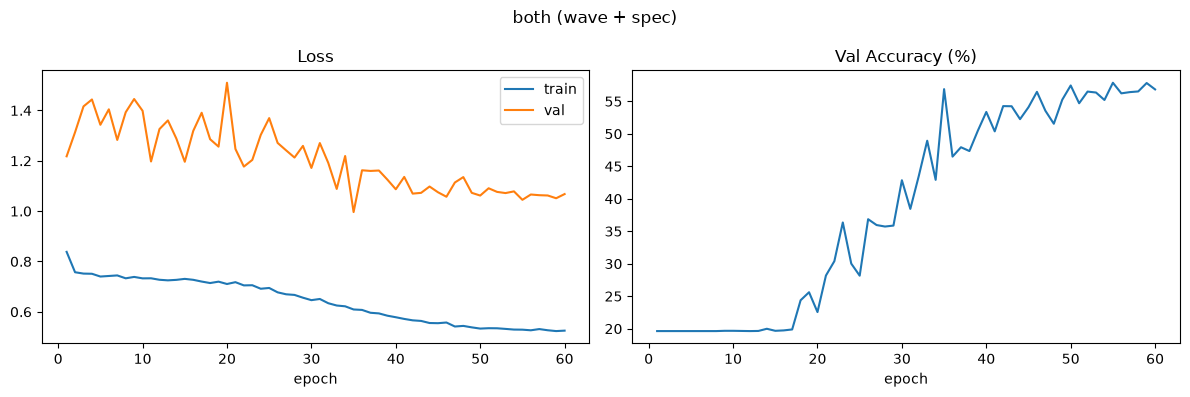

In [ ]:
plot_history(results["both"], name="both (wave + spec)")

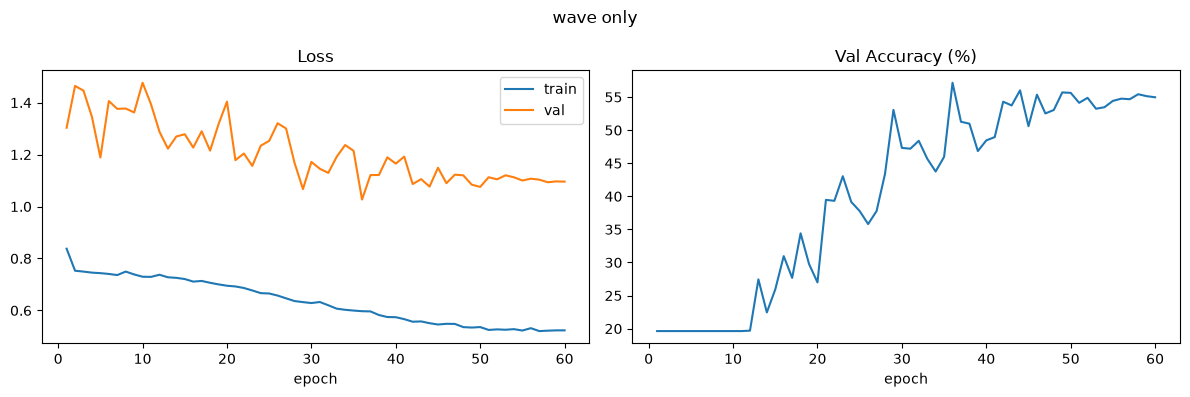

In [ ]:
plot_history(results["wave_only"], name="wave only")

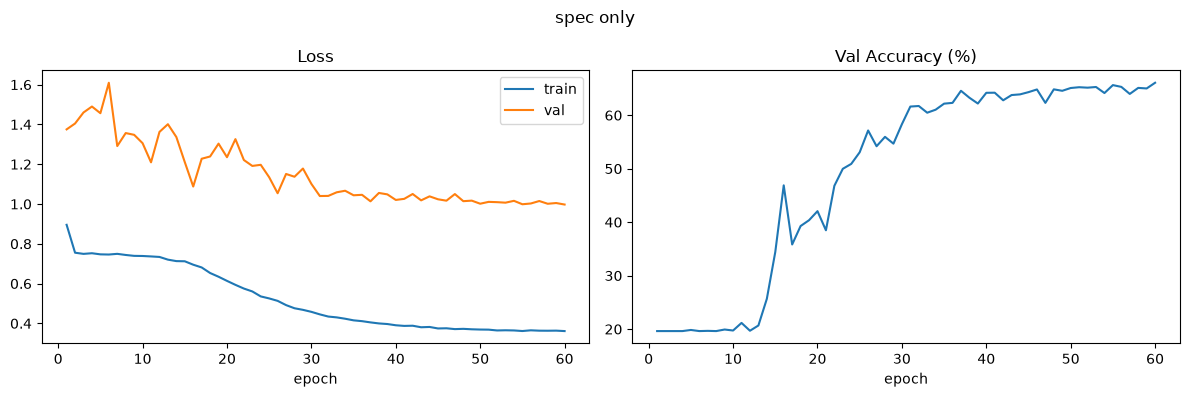

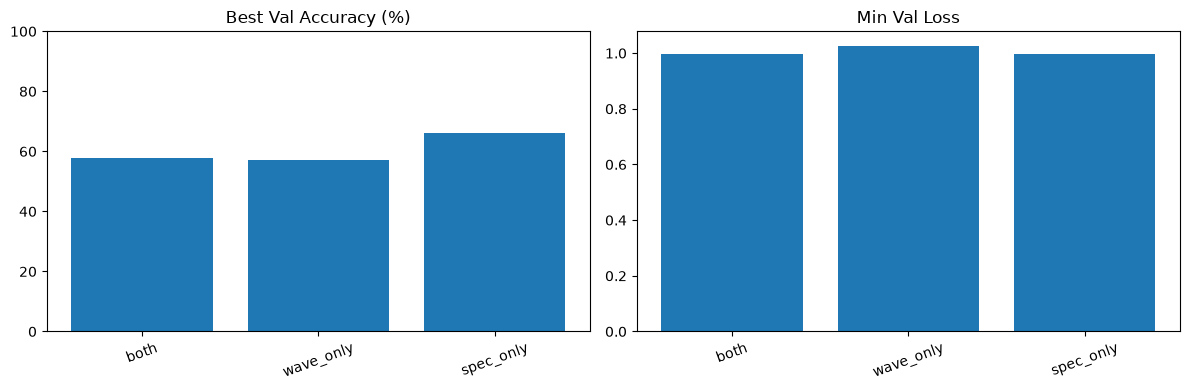

In [ ]:
plot_history(results["spec_only"], name="spec only")

# all wave/spec experiments side by side
plot_comparison(results)

In [ ]:
def results_table(results: dict[str, dict[str, list[float]]]) -> None:
    """Summary table per experiment: max / min / final / avg / std of each metric."""

    rows: list[dict] = []
    for name, hist in results.items():
        for metric in ("train_loss", "val_loss", "val_acc"):
            vals: list[float] = hist[metric]
            rows.append({
                "experiment": name,
                "metric": metric,
                "max": round(max(vals), 4),
                "min": round(min(vals), 4),
                "final": round(vals[-1], 4),
                "avg": round(sum(vals) / len(vals), 4),
                "std": round(float(np.std(vals)), 4),
            })
    df = pl.DataFrame(rows)
    pl.Config.set_ascii_tables()  # ponytail: cp1252 console can't render polars box chars
    with pl.Config(tbl_rows=-1, tbl_cols=-1, tbl_width_chars=120):
        print(df)
    return df


In [ ]:
res_table = results_table(results)
res_table.write_csv("experiment_results_table.csv")
res_table

experiment,metric,max,min,final,avg,std
str,str,f64,f64,f64,f64,f64
"""both""","""train_loss""",0.8382,0.5235,0.5252,0.642,0.086
"""both""","""val_loss""",1.51,0.9961,1.0678,1.2044,0.1274
"""both""","""val_acc""",57.8595,19.6279,56.8353,38.7939,15.1542
"""wave_only""","""train_loss""",0.8377,0.5206,0.5234,0.6333,0.0855
"""wave_only""","""val_loss""",1.4764,1.0269,1.0959,1.2066,0.1137
"""wave_only""","""val_acc""",57.1697,19.6279,54.9749,40.7361,13.7215
"""spec_only""","""train_loss""",0.8954,0.3613,0.3613,0.5211,0.1575
"""spec_only""","""val_loss""",1.6094,0.9973,0.9973,1.1525,0.1576
"""spec_only""","""val_acc""",66.0744,19.6279,66.0744,49.2938,17.9071


In [ ]:
def load_checkpoint(filepath: str, model: nn.Module, optimizer: optim.Optimizer) -> tuple[nn.Module, optim.Optimizer, int, float]:
    print("=> Loading checkpoint")
    # Use weights_only=True for security best practices
    checkpoint: dict = torch.load(filepath, weights_only=True) 
    
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    epoch: int = checkpoint['epoch']
    loss: float = checkpoint['loss']
    return model, optimizer, epoch, loss

def save_checkpoint(model: nn.Module, optimizer: optim.Optimizer, epoch: int, loss: float, filename: str ="checkpoint.pth.tar") -> None:
    print("=> Saving checkpoint")
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }
    torch.save(checkpoint, filename)


In [ ]:


def train(model: nn.Module, epochs: int, patience: int = 20, aug_type: str = "spec") -> dict[str, list[float]]:
    history: dict[str, list[float]] = {"train_loss": [], "val_loss": [], "val_acc": [], "val_f1":[]}

    # Fresh model/optimizer per experiment so runs are independent
    criterion: nn.Module = nn.CrossEntropyLoss(label_smoothing=0.1)
    
    if device.type == "cuda":
        model = torch.compile(model).to(device)  
    else:
        model = model.to(device)  # speed: compile only on CUDA
    
    optimizer: optim.AdamW = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    scaler: torch.amp.GradScaler = torch.amp.GradScaler(enabled=(device.type == "cuda"))
    scheduler: optim.lr_scheduler.CosineAnnealingLR = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=epochs, eta_min=1e-6
    )

    mel_train: SpectMFCCPipeline = mel_train_spec

    # Train loader: AugmentedSubset (WaveformAugmentor) when use_wave, else plain Subset
    train_ds: AugmentedSubset | Subset = Subset(dataset, train_subset.indices)
    
    train_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        train_ds, BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4, sampler=train_sampler  # speed: no worker respawn / keep queues full
    )
    
    val_loader: torch.utils.data.DataLoader = torch.utils.data.DataLoader(
        Subset(dataset, val_subset.indices), BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True,
        persistent_workers=True, prefetch_factor=4,
    )
    
    min_delta: float = 0.001     # Minimum improvement to count as progress
    best_val_loss: float = float('-inf')
    patience_counter: int = 0

    for epoch in range(epochs):
        # Training Phase
        model.train()
        running_loss = 0.0
  
        for waveforms, labels in tqdm(train_loader, desc=f"train {epoch+1}/{epochs}", leave=False):
            waveforms = waveforms.to(device, non_blocking=True)
            labels = labels.long().to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            # Features must run in fp32 OUTSIDE autocast: TimeStretch/complex spectrogram
            # ops produce NaN under fp16 autocast
            images = mel_train(waveforms, labels)  # (B, 3, F, T) — pipeline already returns 3 channels
            if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                images = images.unsqueeze(0)

            with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()

        scheduler.step()

        # Validation Phase
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0
        
        all_preds = []
        all_targets = []

        with torch.inference_mode():
            for waveforms, labels in tqdm(val_loader, desc=f"val {epoch+1}/{epochs}", leave=False):
                waveforms = waveforms.to(device, non_blocking=True)
                labels = labels.long().to(device, non_blocking=True)

                images = mel_eval(waveforms)  # no labels -> no spec aug; fp32 outside autocast
                if images.ndim == 3:  # pipeline dropped the channel dim on a 1-sample batch
                    images = images.unsqueeze(0)

                with torch.amp.autocast(device_type=device.type, enabled=(device.type == "cuda")):
                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    
                all_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                all_targets.extend(labels.cpu().numpy())
                    
                

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                total += labels.size(0)
                correct += predicted.eq(labels).sum().item()

        val_macro_f1 = f1_score(all_targets, all_preds, average='macro')
        train_epoch_loss = running_loss / len(train_loader)
        val_epoch_loss = val_loss / len(val_loader)
        val_accuracy = 100.0 * correct / total
        

        history["train_loss"].append(train_epoch_loss)
        history["val_loss"].append(val_epoch_loss)
        history["val_f1"].append(val_epoch_loss)
        history["val_acc"].append(val_accuracy)

        print(f"train Epoch [{epoch+1}/{num_epochs}] -> "
              f"Train Loss: {train_epoch_loss:.4f} | "
              f"Val Loss: {val_epoch_loss:.4f} | "
              f"Val F1: {val_macro_f1:.4f} | "
              f"Val Acc: {val_accuracy:.2f}%")
        
        
        if val_macro_f1 > (best_val_loss - min_delta):
            best_val_loss = val_macro_f1
            print("saving new checkpoint. F1 Improved")
            save_checkpoint(
                model, optimizer, epoch, val_macro_f1, 
                filename=f"saved_models\\{model.__class__.__name__}_{aug_type}_checkpoint_{train_epoch_loss:.4f}_{val_macro_f1:.2f}.pth.tar"
            )
            
        """    
        else:
            patience_counter += 1  # No significant improvement, tick up the counter
            print(f"=> No improvement. Patience: {patience_counter}/{patience}")
            
            if patience_counter >= patience:
                print("Early stopping triggered! Halting training.")
                break # Break out of the epoch loop"""


    return history

In [14]:
model: nn.Module = DefaultCNN(3)
history = train(model, 512)
#pl = pl.DataFrame(history)

train 1/512:   0%|          | 0/300 [00:34<?, ?it/s]

val 1/512:   0%|          | 0/38 [00:01<?, ?it/s]

train 2/512:   0%|          | 0/300 [00:00<?, ?it/s]

val 2/512:   0%|          | 0/38 [00:00<?, ?it/s]

train 3/512:   0%|          | 0/300 [00:00<?, ?it/s]

...

val 510/512:   0%|          | 0/38 [00:00<?, ?it/s]

train 511/512:   0%|          | 0/300 [00:00<?, ?it/s]

val 511/512:   0%|          | 0/38 [00:00<?, ?it/s]

train 512/512:   0%|          | 0/300 [00:00<?, ?it/s]

val 512/512:   0%|          | 0/38 [00:00<?, ?it/s]